### START OF THE ASSIGNMENT ###

#### Importing of libraries 

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import copy
import matplotlib.pyplot as plt
pd.set_option("display.precision", 2)
pd.set_option('display.max_rows', 600)
pd.set_option('display.max_columns', 600)
pd.set_option('display.width', 10000)
pd.set_option('display.max_colwidth',1000)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
sns.set(style="whitegrid")

#### Loading file and basic column cleaning. 

In [2]:
data = pd.read_csv('loan.csv')
data=data.loc[data['loan_status']!='Current']
null_col_list=data.isnull().sum(axis=0)
data.drop(list(null_col_list.where(null_col_list==data.shape[0]).dropna().index),axis=1,inplace=True)
#del data['next_pymnt_d']#less data and we are not interested in borrower's next payment cycle info
del data['pymnt_plan']#only one value i.e. n
del data['application_type']#only on e value i.e INDIVIDUAL
del data['policy_code']#only one value i.e 1
del data['tax_liens']#only one value i.e 0
del data['delinq_amnt']#only one value i.e 0
del data['chargeoff_within_12_mths']#only one value i.e 0
del data['acc_now_delinq']#only one value i.e 0
del data['collections_12_mths_ex_med']#only one value i.e 0
del data['initial_list_status']#only one value i.e f
del data['mths_since_last_delinq']#very limited data and substituing the average values will not provide any insights
del data['mths_since_last_record']#very limited data 
data.shape

C:\Users\ramch\Software\lib\site-packages\IPython\core\interactiveshell.py:3063: DtypeWarning: Columns (47) have mixed types.Specify dtype option on import or set low_memory=False.
  interactivity=interactivity, compiler=compiler, result=result)


(38577, 45)

#### Data Cleaning 

In [3]:
#filling the mean value of emp length
data['emp_length'].describe()
data['emp_length']=data['emp_length'].apply(lambda x : 0 if x =='< 1 year' else int(x[0:2]) if pd.notnull(x) else np.nan)
data['emp_length'].fillna(value=round(data[~pd.isnull(data['emp_length'])]['emp_length'].mean()),inplace=True)
#maxmium frequency of pub_rec_bankruptcies is 0
data['pub_rec_bankruptcies'].fillna(value=0,inplace=True)
data['int_rate']=data['int_rate'].apply(lambda x : float(x[:-1]))
# As None and Other are same just with Different Categorical values. So merging it together.
data['home_ownership']=data['home_ownership'].apply(lambda x : 'OTHER' if x=='NONE' else x )

#### Deriving columns

####  All the keywords with "level" is for changing numerical to categorical attribute. Ranging them helps in better analysis. 
#### loan_income_ratio is considered as it helps to determine the capacity of the borrower to payback the loan with his/her current income status
#### revol_util is also important as it indicates the amount of credits used/available of the borrower.

In [4]:
#derived columns
data['int_rate_level']=data['int_rate'].apply(lambda x : 'High' if x>18 else 'Medium' if x<=18 and x> 10 else 'Low')
data['loan_amnt_level']=data['loan_amnt'].apply(lambda x : '< 4k' if x<=4000 else '4k - 10k' if x >4000 and x<=10000 else '10k- 20k' if x>10000 and x <=20000 else '> 20k')
data['annual_inc_level']=data['annual_inc'].apply(lambda x : '< 30k' if x<=30000 else '30k - 50k' if x >30000 and x<=50000 else '50k- 100k' if x>50000 and x <=100000 else '> 100k')
data['has_desc']=data['desc'].apply(lambda x: 1 if pd.notnull(x) else 0)
data['dti_level'] = data['dti'].apply(lambda x: 'low' if x<12 else 'medium' if x>=12 and x<20 else 'high')
data['loan_income_ratio']=(data['loan_amnt']/data['annual_inc'])*100
data['loan_income_ratio_level'] = data['loan_income_ratio'].apply(lambda x : 'Low' if x <15 else 'Medium' if x>=15 and x<50 else 'High')
data['revol_util']=data['revol_util'].apply(lambda x : float(str(x)[:-1]) if pd.notnull(x) else 0)
data['revol_util_level']=data['revol_util'].apply(lambda x: 'Low' if x<30 else 'Medium' if x>=30 and x<60 else 'High')


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 38577 entries, 0 to 39716
Data columns (total 53 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       38577 non-null  int64  
 1   member_id                38577 non-null  int64  
 2   loan_amnt                38577 non-null  int64  
 3   funded_amnt              38577 non-null  int64  
 4   funded_amnt_inv          38577 non-null  float64
 5   term                     38577 non-null  object 
 6   int_rate                 38577 non-null  float64
 7   installment              38577 non-null  float64
 8   grade                    38577 non-null  object 
 9   sub_grade                38577 non-null  object 
 10  emp_title                36191 non-null  object 
 11  emp_length               38577 non-null  float64
 12  home_ownership           38577 non-null  object 
 13  annual_inc               38577 non-null  float64
 14  verification_status   

# Univariate Ananlysis

#### Only Charged  off and Default is considered. Since we cannot conclude for current, it is removed off.

#### PLOT 1 : Analyzing grade for both the loan status. This will help in understanding if grade plays a significant role in the two.

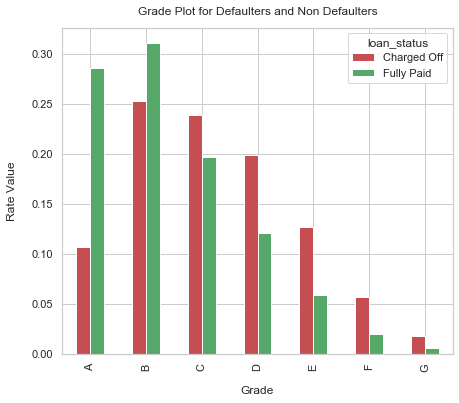

In [6]:
pivot_data = pd.pivot_table(data,columns=['loan_status'],index=['grade'],values='member_id',aggfunc=[len])
pivot_data.columns=pivot_data.columns.droplevel()

#normalizing the values
pivot_data['Fully Paid']=pivot_data['Fully Paid'].apply(lambda x : x/pivot_data['Fully Paid'].sum())
pivot_data['Charged Off']=pivot_data['Charged Off'].apply(lambda x : x/pivot_data['Charged Off'].sum())

pivot_data.plot.bar(figsize=(7, 6),color=["r","g"])
plt.xlabel("Grade", labelpad=14)
plt.ylabel("Rate Value", labelpad=14)
plt.title("Grade Plot for Defaulters and Non Defaulters", y=1.02);
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'Century'

#### Result: Above Graph shows us that if Loan Grade is above 'D' then the borrower is most likely to default.

#### PLOT 2 :  Analyzing Term for both the loan status. This will help in understanding if Term plays a significant role in the two

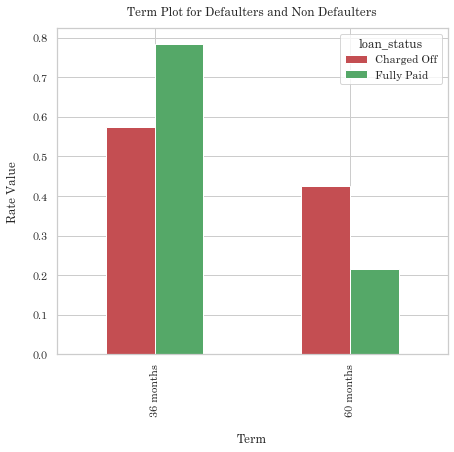

In [7]:

pivot_data = pd.pivot_table(data,columns=['loan_status'],index=['term'],values='member_id',aggfunc=[len])
pivot_data.columns=pivot_data.columns.droplevel()

#normalizing the values
pivot_data['Fully Paid']=pivot_data['Fully Paid'].apply(lambda x : x/pivot_data['Fully Paid'].sum())
pivot_data['Charged Off']=pivot_data['Charged Off'].apply(lambda x : x/pivot_data['Charged Off'].sum())

pivot_data.plot.bar(figsize=(7, 6),color=["r","g"])
plt.xlabel("Term", labelpad=14)
plt.ylabel("Rate Value", labelpad=14)
plt.title("Term Plot for Defaulters and Non Defaulters", y=1.02);
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'Century'

#### Result: Higher the term, higher are the chances of defaulting.

#### PLOT3:  Analyzing Home Ownership for both the loan status. This will help in understanding if home ownership plays a significant role in the two

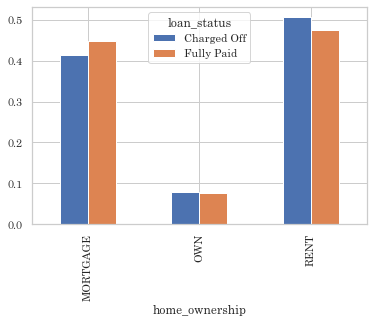

In [8]:

pivot_data = pd.pivot_table(data.loc[data['home_ownership']!='OTHER'],columns=['loan_status'],index=['home_ownership'],values='member_id',aggfunc=[len])
pivot_data.columns=pivot_data.columns.droplevel()

#normalizing the values
pivot_data['Fully Paid']=pivot_data['Fully Paid'].apply(lambda x : x/pivot_data['Fully Paid'].sum())
pivot_data['Charged Off']=pivot_data['Charged Off'].apply(lambda x : x/pivot_data['Charged Off'].sum())

pivot_data.plot.bar()

#### Result : There is a slight chance that if a borrower lives in a rented house, he/she may default.

#### PLOT 4:  Analyzing Verification Status for both the loan status. This will help in understanding if home ownership plays a significant role in the two

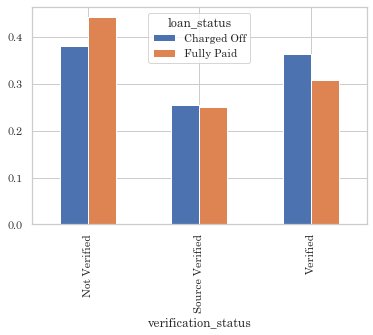

In [9]:
pivot_data = pd.pivot_table(data,columns=['loan_status'],index=['verification_status'],values='member_id',aggfunc=[len])
pivot_data.columns=pivot_data.columns.droplevel()

#normalizing the values
pivot_data['Fully Paid']=pivot_data['Fully Paid'].apply(lambda x : x/pivot_data['Fully Paid'].sum())
pivot_data['Charged Off']=pivot_data['Charged Off'].apply(lambda x : x/pivot_data['Charged Off'].sum())

pivot_data.plot.bar()

#### Result: The statistics says there are more defaulters in verified section. This may need some discussions with the third party on the verification protocols. 

#### PLOT 5a: Analyzing Purpose for both the loan status. This will help in understanding if Purpose plays a significant role in the two

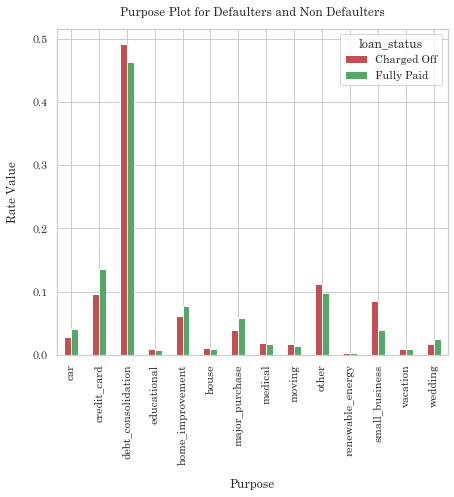

In [10]:

pivot_data = pd.pivot_table(data,columns=['loan_status'],index=['purpose'],values='member_id',aggfunc=[len])
pivot_data.columns=pivot_data.columns.droplevel()

#normalizing the values
pivot_data['Fully Paid']=pivot_data['Fully Paid'].apply(lambda x : x/pivot_data['Fully Paid'].sum())
pivot_data['Charged Off']=pivot_data['Charged Off'].apply(lambda x : x/pivot_data['Charged Off'].sum())

pivot_data.plot.bar(figsize=(7, 6),color=["r","g"])
plt.xlabel("Purpose", labelpad=14)
plt.ylabel("Rate Value", labelpad=14)
plt.title("Purpose Plot for Defaulters and Non Defaulters", y=1.02);
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'Century'

#### Result: From above graph we can conclude that borrowers who ask for "small business" have higher probablity of defaulting. Also, maximum loans are taken for "Debt_consilidation"

#### PLOT 5b: Within Debt_consolidation, the plot is for analyzing the distribution of mean of Loan/Income ratio across grade and home_ownership for defaulters

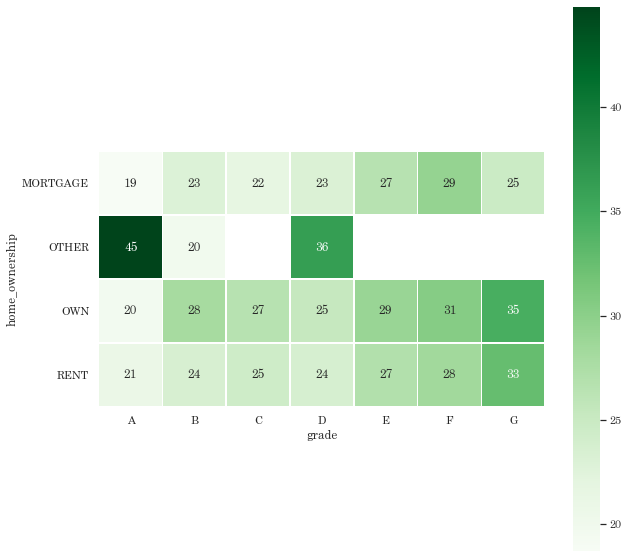

In [11]:
pivot_data = pd.pivot_table(data.loc[(data['purpose']=='debt_consolidation')&(data['loan_status']=='Charged Off')],columns=['grade'],index=['home_ownership'],values='loan_income_ratio')
fig, ax = plt.subplots(figsize=(10,10))   
sns.heatmap(pivot_data,cmap = "Greens",linewidths=0.6, annot=True, square=True,ax=ax)
plt.show()

#### Result :  We can conclude that if a borrower doesn't mention his/her home ownership(i.e. other or None) and lies in grade A  with purpose of debt_consolidation,  loan to income ratio is observed to be very high. So, if a borrower lies in these conditions, there are a high chances of defaulting.

#### PLOT 5c : Within Debt_consolidation, the plot is for analyzing the distribution of mean of revol_util ratio across grade and home_ownership for defaulters

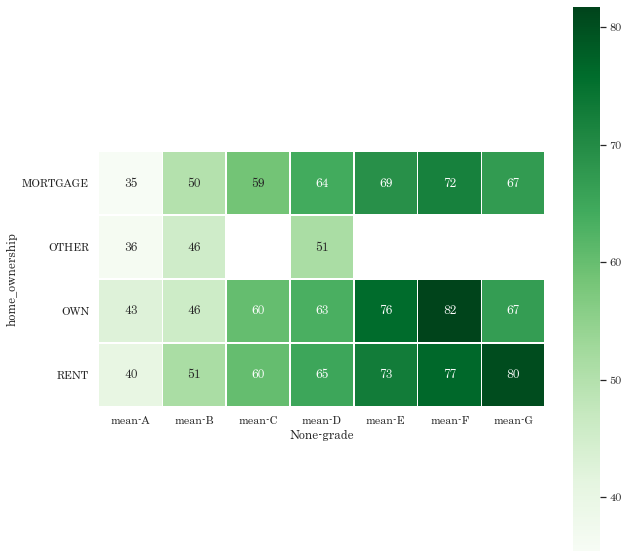

In [12]:

pivot_data = pd.pivot_table(data.loc[(data['purpose']=='debt_consolidation')&(data['loan_status']=='Charged Off')],columns=['grade'],index=['home_ownership'],values='revol_util',aggfunc=[np.mean])
fig, ax = plt.subplots(figsize=(10,10))   
sns.heatmap(pivot_data,cmap = "Greens",linewidths=0.6, annot=True, square=True,ax=ax)
plt.show()

#### Result: From above graph, we can say that if a borrower with purpose of  debt_consolidation, having a Revolving Utilization rate greater than 70% and staying in owned or rented house, then he/she may have more probability of defaulting.

#### PLOT 6a: The plot is for analyzing between loan status and Public record for bankruptcies.

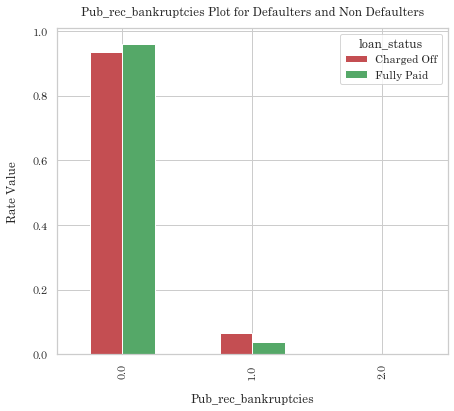

In [13]:

pivot_data = pd.pivot_table(data,columns=['loan_status'],index=['pub_rec_bankruptcies'],values='member_id',aggfunc=[len])
pivot_data.columns=pivot_data.columns.droplevel()

#normalizing the values
pivot_data['Fully Paid']=pivot_data['Fully Paid'].apply(lambda x : x/pivot_data['Fully Paid'].sum())
pivot_data['Charged Off']=pivot_data['Charged Off'].apply(lambda x : x/pivot_data['Charged Off'].sum())

pivot_data.plot.bar(figsize=(7, 6),color=["r","g"])
plt.xlabel("Pub_rec_bankruptcies", labelpad=14)
plt.ylabel("Rate Value", labelpad=14)
plt.title("Pub_rec_bankruptcies Plot for Defaulters and Non Defaulters", y=1.02);
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'Century'

#### Result:  Borrower with a  Public Bankruptcy record  has a higher chance of defaulting

#### PLOT 6b: The plot is for analyzing home_ownership and  Public record for bankruptcies with median of loan_income ratio for Defaulters.

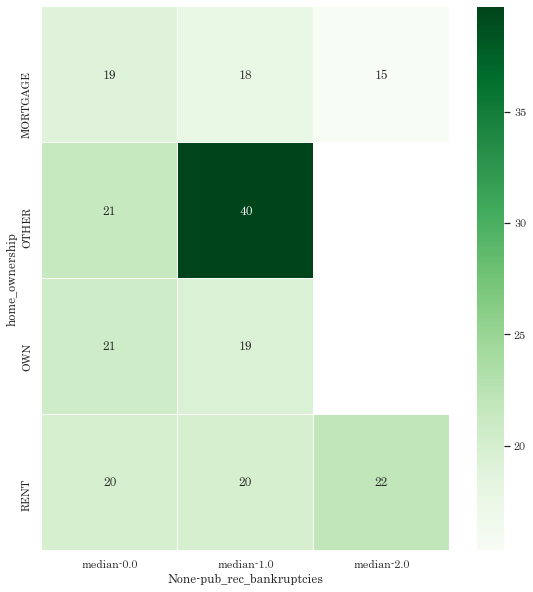

In [14]:

pivot_data = pd.pivot_table(data.loc[data['loan_status']=='Charged Off'],columns=['pub_rec_bankruptcies'],index=['home_ownership'],values='loan_income_ratio',aggfunc=[np.median])
fig, ax = plt.subplots(figsize=(10,10))   
sns.heatmap(pivot_data,cmap = "Greens",linewidths=0.6, annot=True, square=True,ax=ax)
plt.show()

####  Result :If the borrower has mentioned for the category of home ownership as "Other " or "None" and if he/she has single public record of bankruptcy then borrower has a high chance of defaulting as the Loan/Income ratio is also High.

#### PLOT 6c: The plot is for analyzing emp length relationship with annual income and Public record for bankruptcies  for defaulters

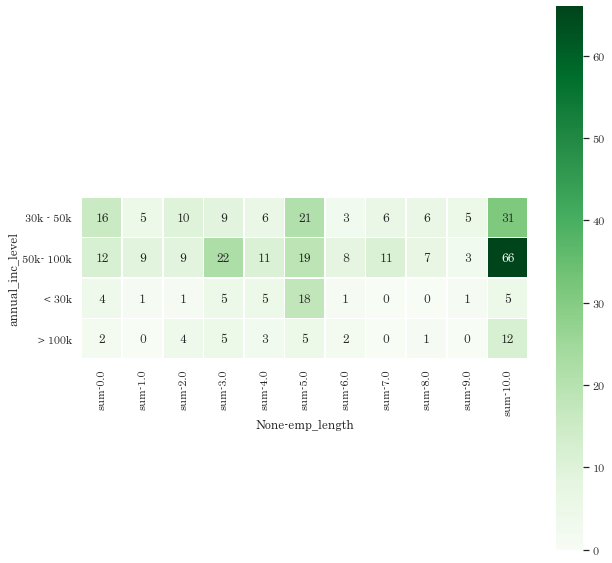

In [15]:

pivot_data = pd.pivot_table(data.loc[data['loan_status']=='Charged Off'],columns=['emp_length'],index=['annual_inc_level'],values='pub_rec_bankruptcies',aggfunc=[sum])
fig, ax = plt.subplots(figsize=(10,10))   
sns.heatmap(pivot_data,cmap = "Greens",linewidths=0.6, annot=True, square=True,ax=ax)
plt.show()

#### Result: We observe that a borrower with an experience level 10+ and having an income of around 50k-100k has more of public record for bankruptcy. So, we can check for the above conditions when a borrower applies for a loan.

#### PLOT 7a: The plot is for analyzing int_rate_level relationship with both the loan_status

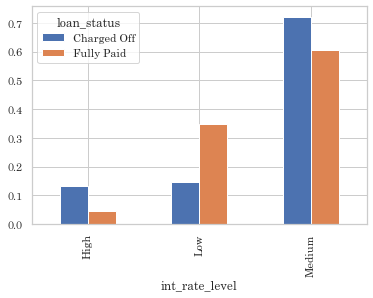

In [16]:
pivot_data = pd.pivot_table(data,columns=['loan_status'],index=['int_rate_level'],values='member_id',aggfunc=[len])
pivot_data.columns=pivot_data.columns.droplevel()

#normalizing the values
pivot_data['Fully Paid']=pivot_data['Fully Paid'].apply(lambda x : x/pivot_data['Fully Paid'].sum())
pivot_data['Charged Off']=pivot_data['Charged Off'].apply(lambda x : x/pivot_data['Charged Off'].sum())

pivot_data.plot.bar()

#### Result: If the Interest Rate is Medium(i.e between 10 to 18) or High(i.e. above 18) then the borrower has a higher chance of defaulting

#### PLOT 7b: The box plot is for analyzing the median of the interest rate  for  both the loan_status

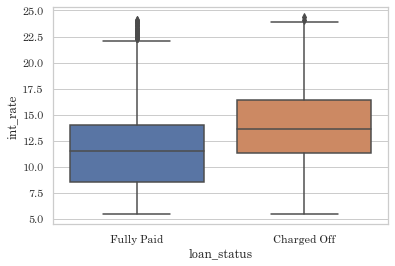

In [17]:

sns.boxplot(x='loan_status',y='int_rate',data=data, palette="deep")

#### Result:  As we can clearly observe from the box-plot, defaulters are those with int_rate of 13% or more. 

#### PLOT 8: The box plot is for analyzing relationship between loan_amount asked by the borrower and  both the loan_status

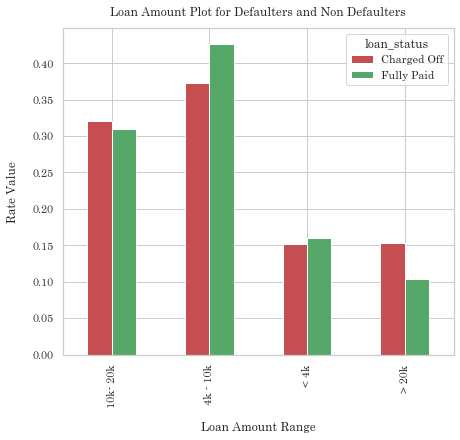

In [18]:
pivot_data = pd.pivot_table(data,columns=['loan_status'],index=['loan_amnt_level'],values='member_id',aggfunc=[len])
pivot_data.columns=pivot_data.columns.droplevel()
pivot_data.reset_index()
#normalizing the values
pivot_data['Fully Paid']=pivot_data['Fully Paid'].apply(lambda x : x/pivot_data['Fully Paid'].sum())
pivot_data['Charged Off']=pivot_data['Charged Off'].apply(lambda x : x/pivot_data['Charged Off'].sum())

pivot_data.plot.bar(figsize=(7, 6),color=["r","g"])
plt.xlabel("Loan Amount Range", labelpad=14)
plt.ylabel("Rate Value", labelpad=14)
plt.title("Loan Amount Plot for Defaulters and Non Defaulters", y=1.02);
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'Century'

#### Result:  If the Borrower asks for Loan amount,  greater than 10k, probability increases for defaulting ( if greater than 20k, more chances of defaulting)

#### PLOT 9: The box plot is for analyzing relationship between annual_income_level  of  the borrower and  both the loan_status

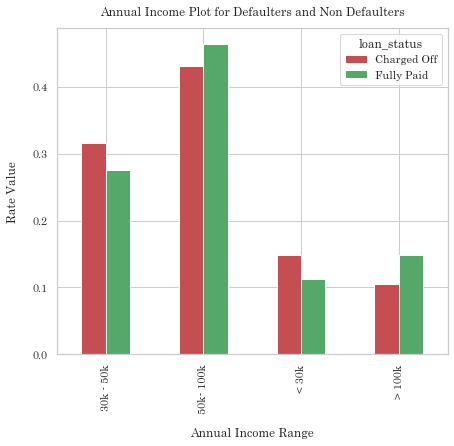

In [19]:

pivot_data = pd.pivot_table(data,columns=['loan_status'],index=['annual_inc_level'],values='member_id',aggfunc=[len])
pivot_data.columns=pivot_data.columns.droplevel()
pivot_data.reset_index()
#normalizing the values
pivot_data['Fully Paid']=pivot_data['Fully Paid'].apply(lambda x : x/pivot_data['Fully Paid'].sum())
pivot_data['Charged Off']=pivot_data['Charged Off'].apply(lambda x : x/pivot_data['Charged Off'].sum())

pivot_data.plot.bar(figsize=(7, 6),color=["r","g"])
plt.xlabel("Annual Income Range", labelpad=14)
plt.ylabel("Rate Value", labelpad=14)
plt.title("Annual Income Plot for Defaulters and Non Defaulters", y=1.02);
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'Century'

#### Result :  Borrower with an income of less than 50K has a higher chances of defaulting.

#### PLOT 10: The plot is for analyzing whether lack of description indicates defaulting tendencies

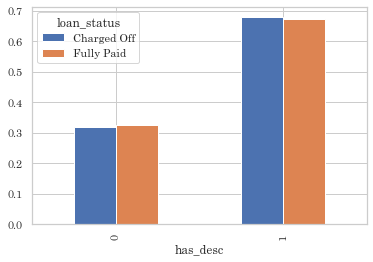

In [20]:
pivot_data = pd.pivot_table(data,columns=['loan_status'],index=['has_desc'],values='member_id',aggfunc=[len])
pivot_data.columns=pivot_data.columns.droplevel()
pivot_data.reset_index()
#normalizing the values
pivot_data['Fully Paid']=pivot_data['Fully Paid'].apply(lambda x : x/pivot_data['Fully Paid'].sum())
pivot_data['Charged Off']=pivot_data['Charged Off'].apply(lambda x : x/pivot_data['Charged Off'].sum())

pivot_data.plot.bar()

#### Result: We can't derive any insights from description column.

#### PLOT 11 : The plot for analyzing dti_level with both the loan_status

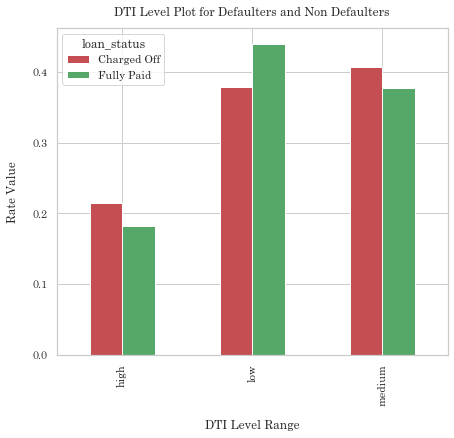

In [21]:
pivot_data = pd.pivot_table(data,columns=['loan_status'],index=['dti_level'],values='member_id',aggfunc=[len])
pivot_data.columns=pivot_data.columns.droplevel()
pivot_data.reset_index()
#normalizing the values
pivot_data['Fully Paid']=pivot_data['Fully Paid'].apply(lambda x : x/pivot_data['Fully Paid'].sum())
pivot_data['Charged Off']=pivot_data['Charged Off'].apply(lambda x : x/pivot_data['Charged Off'].sum())

pivot_data.plot.bar(figsize=(7, 6),color=["r","g"])
plt.xlabel("DTI Level Range", labelpad=14)
plt.ylabel("Rate Value", labelpad=14)
plt.title("DTI Level Plot for Defaulters and Non Defaulters", y=1.02);
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'Century'

#### Result : If the DTI is medium or high then chances of the borrower to d efault is high. More specifically,  with the dti greater than 12.

#### PLOT 12 : The plot is for analyzing the ratio, loan/income, with both the loan_status

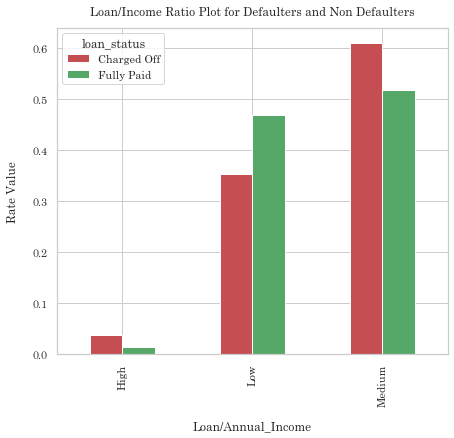

In [22]:

pivot_data = pd.pivot_table(data,columns=['loan_status'],index=['loan_income_ratio_level'],values='member_id',aggfunc=[len])
pivot_data.columns=pivot_data.columns.droplevel()
pivot_data.reset_index()
#normalizing the values
pivot_data['Fully Paid']=pivot_data['Fully Paid'].apply(lambda x : x/pivot_data['Fully Paid'].sum())
pivot_data['Charged Off']=pivot_data['Charged Off'].apply(lambda x : x/pivot_data['Charged Off'].sum())

pivot_data.plot.bar(figsize=(7, 6),color=["r","g"])
plt.xlabel("Loan/Annual_Income", labelpad=14)
plt.ylabel("Rate Value", labelpad=14)
plt.title("Loan/Income Ratio Plot for Defaulters and Non Defaulters", y=1.02);
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'Century'

#### Result:  If the loan_amount asked, is greater than 15% of the borrower's annual income then that borrower is highly likely to default

#### PLOT 13a: The plot is for analyzing the revol_util_level, with both the loan_status

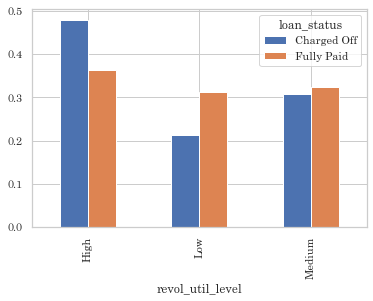

In [23]:
pivot_data = pd.pivot_table(data,columns=['loan_status'],index=['revol_util_level'],values='member_id',aggfunc=[len])
pivot_data.columns=pivot_data.columns.droplevel()
pivot_data.reset_index()
#normalizing the values
pivot_data['Fully Paid']=pivot_data['Fully Paid'].apply(lambda x : x/pivot_data['Fully Paid'].sum())
pivot_data['Charged Off']=pivot_data['Charged Off'].apply(lambda x : x/pivot_data['Charged Off'].sum())

pivot_data.plot.bar()
#data.loc[data['loan_status']=='Charged Off']['revol_util'].plot.hist()

#### PLOT 13b: The plot is for analyzing the revol_util_level, with both the loan_status

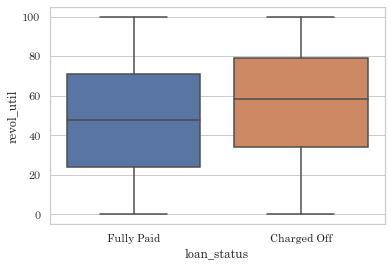

In [24]:

sns.boxplot(x='loan_status',y='revol_util',data=data)

#### Borrower having revolving utilization rate higher than 60% , have higher chances of defaulting

#### PLOT 14: Box plot for loan amount analysis

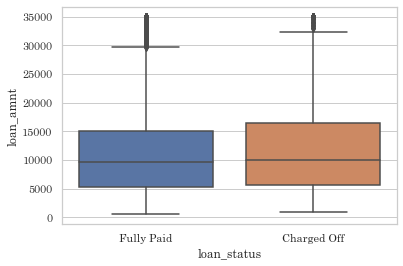

In [25]:
sns.boxplot(x='loan_status',y='loan_amnt',data=data)

#### PLOT 15:  Since purpose with debt consolidation and verification_status as verified has highest number of defaulters, the plot is to identify any pattern in them using loan_income ratio.

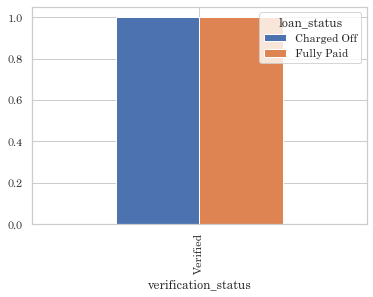

In [26]:

pivot_data = pd.pivot_table(data.loc[(data['purpose']=='debt_consolidation')&(data['verification_status']=='Verified')],columns=['loan_status'],index=['verification_status'],values='loan_income_ratio',aggfunc=[np.mean])
pivot_data.columns=pivot_data.columns.droplevel()
pivot_data.reset_index()
#normalizing the values
pivot_data['Fully Paid']=pivot_data['Fully Paid'].apply(lambda x : x/pivot_data['Fully Paid'].sum())
pivot_data['Charged Off']=pivot_data['Charged Off'].apply(lambda x : x/pivot_data['Charged Off'].sum())

pivot_data.plot.bar()

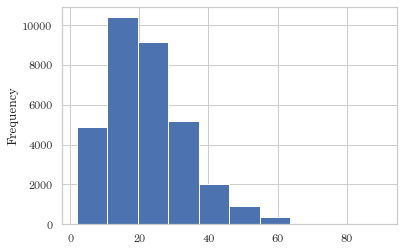

In [27]:
#TEST PLOT 
data.loc[data['loan_status']=='Fully Paid']['total_acc'].plot.hist()

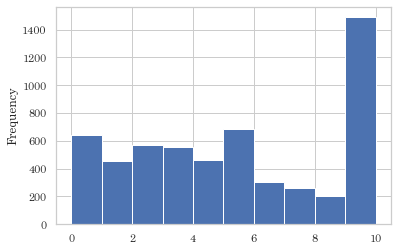

In [28]:
#TEST PLOT
data.loc[data['loan_status']=='Charged Off']['emp_length'].plot.hist()

#### PLOT 16:  The plot is check the pattern amongst employment length with loan_income ratio and annual_inc level

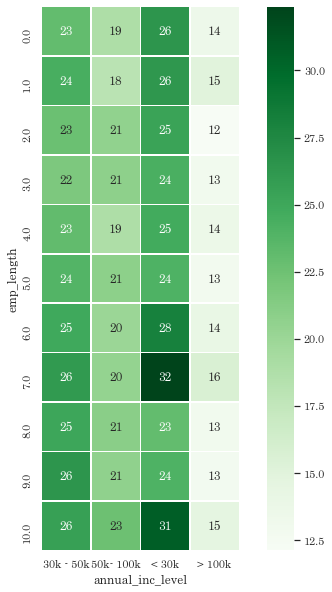

In [29]:

pivot_data = pd.pivot_table(data.loc[data['loan_status']=='Charged Off'],columns=['annual_inc_level'],index=['emp_length'],values='loan_income_ratio')
fig, ax = plt.subplots(figsize=(10,10))   
sns.heatmap(pivot_data,cmap = "Greens",linewidths=0.6, annot=True, square=True,ax=ax)
plt.show()

#### Result : From above graph, we can conclude that number of borrowers having high loan to income ratio lies in the income group of  less that 30K and with an emp_length of 7 or 10+ more likely to default. 

#### PLOT 17 : The plot is check the pattern/trend in grade and home_ownership with loan_income ratio

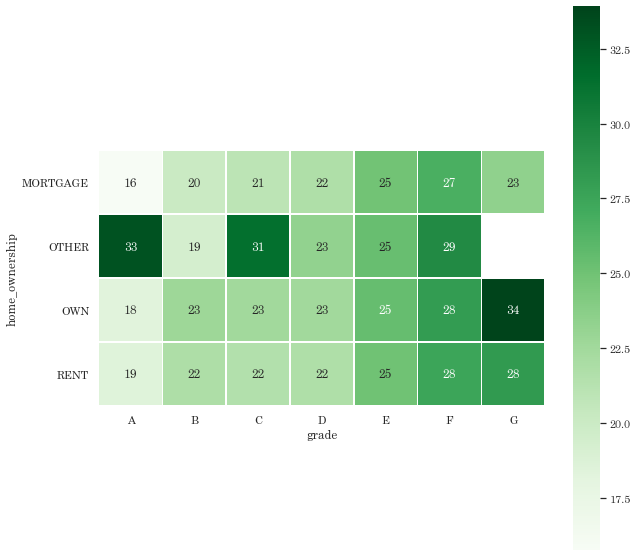

In [30]:
pivot_data = pd.pivot_table(data.loc[data['loan_status']=='Charged Off'],columns=['grade'],index=['home_ownership'],values='loan_income_ratio',aggfunc=np.mean)
fig, ax = plt.subplots(figsize=(10,10))   
sns.heatmap(pivot_data,cmap = "Greens",linewidths=0.6, annot=True, square=True,ax=ax)
plt.show()

In [31]:
data['share_monthly_inc_as_dept']=(data['installment']*12)/data['annual_inc']

In [32]:
data['share_monthly_inc_as_dept'].describe()

count   38577.000
mean        0.066
std         0.040
min         0.000
25%         0.035
50%         0.058
75%         0.088
max         0.320
Name: share_monthly_inc_as_dept, dtype: float64

#### PLOT 18: The plot is to check trends/pattern for defaulters between annual_income level, home ownership and loan_amount.

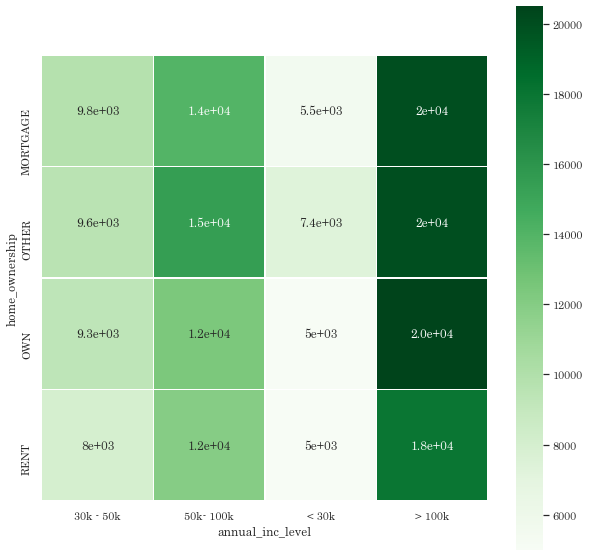

In [33]:
pivot_data = pd.pivot_table(data.loc[data['loan_status']=='Charged Off'],columns=['annual_inc_level'],index=['home_ownership'],values='loan_amnt',aggfunc=np.median)
fig, ax = plt.subplots(figsize=(10,10))   
sns.heatmap(pivot_data,cmap = "Greens",linewidths=0.6, annot=True, square=True,ax=ax)
plt.show()

#### PLOT 19: The plot is to check trends/pattern for defaulters between annual_income level, loan_amount_level.

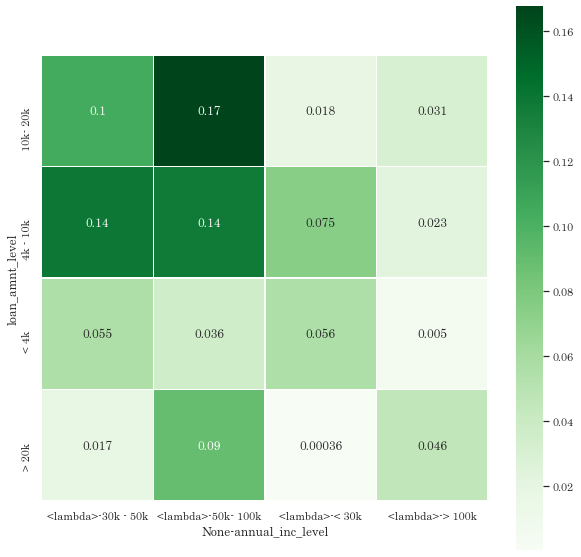

In [34]:
#5627 is number of charged off records
pivot_data = pd.pivot_table(data.loc[data['loan_status']=='Charged Off'],columns=['annual_inc_level'],index=['loan_amnt_level'],values='member_id',aggfunc=[lambda x : len(x)/5627])
fig, ax = plt.subplots(figsize=(10,10))   
sns.heatmap(pivot_data,cmap = "Greens",linewidths=0.6, annot=True, square=True,ax=ax)
plt.show()

#### RESULT: As we saw above, more number of defaulters lie with an annual income of  50K-100k and with a loan amount of 10k-20k.

### END OF THE ASSIGNMENT